**Before running this notebook:**

1. Download the data: `uv run python -m ev_gap.download`
2. Run the data pipeline: `uv run python -m ev_gap.pipeline`. This notebook reads its output (`data/processed/districts.csv`).
3. Select the kernel of the `.venv` in this folder.

# Expected charging points per district: models and gaps

Goal: for every district, estimate how many public charging points a typical district with the same number of electric cars, residents and density has. The gap is the actual number compared with that expected number, in percent.

Three models are compared, always with cross validation:

| Model | Idea |
|---|---|
| Baseline ratio | Every district gets BEV divided by the national BEV per charging point |
| Linear regression on logs | The main model. Works in percentages: 10% more cars means x% more points |
| Gradient boosting | The comparison model. Can find curves and interactions the linear model cannot |

Inputs of the models: BEV, population, density (from `config.FEATURE_COLUMNS`). The target is the number of charging points. Columns built from the target are never inputs.

**How the numbers are made.** In 5-fold cross validation the districts are split into 5 groups. Each group is predicted by a model that was trained on the other 4. So the expected value of a district never comes from a model that saw that district. The baseline ratio is also computed from the training districts only.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

from ev_gap import config
from ev_gap.model import (
    BASELINE, BOOSTING, LINEAR, build_gap_table, cross_validate, make_models, random_folds, state_of, summarise,
)
from ev_gap.pipeline import load_districts

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})

districts = load_districts()
models = make_models()
print(len(districts), "districts | inputs:", config.FEATURE_COLUMNS, "| target:", config.TARGET)

399 districts | inputs: ['bev', 'population', 'density'] | target: charging_points


## 1. Which model predicts best?

Three error measures, smaller is better for all of them:

- **median_error_pct:** the typical error in percent of the actual number of points. Easy to read.
- **mae_points:** the average error in charging points. Dominated by the large districts.
- **log_rmse:** the error on the log scale. 0.3 means a typical miss by a factor of about 1.35.

Two ways to split:
- **Random folds:** districts are assigned to 5 groups at random.
- **Folds by federal state:** whole states are held out. This is harder, because neighbouring districts are similar and a random split lets them help each other.

In [2]:
out_of_fold, per_fold = cross_validate(districts, models, random_folds())
_, per_fold_state = cross_validate(districts, models, GroupKFold(n_splits=5), groups=state_of(districts))

print("Random 5-fold cross validation (mean and standard deviation over the folds)")
print(summarise(per_fold).to_string())
print()
print("Cross validation by federal state")
print(summarise(per_fold_state).to_string())

Random 5-fold cross validation (mean and standard deviation over the folds)
                          mae_points         median_error_pct        log_rmse       
                                mean     std             mean    std     mean    std
model                                                                               
Baseline ratio               156.900  37.155           26.601  4.776    0.384  0.044
Gradient boosting            148.633  38.278           22.610  2.742    0.334  0.037
Linear regression on logs    133.738  30.230           21.132  3.064    0.324  0.032

Cross validation by federal state
                          mae_points         median_error_pct        log_rmse       
                                mean     std             mean    std     mean    std
model                                                                               
Baseline ratio               162.669  50.509           28.202  4.668    0.394  0.053
Gradient boosting            173.130  8

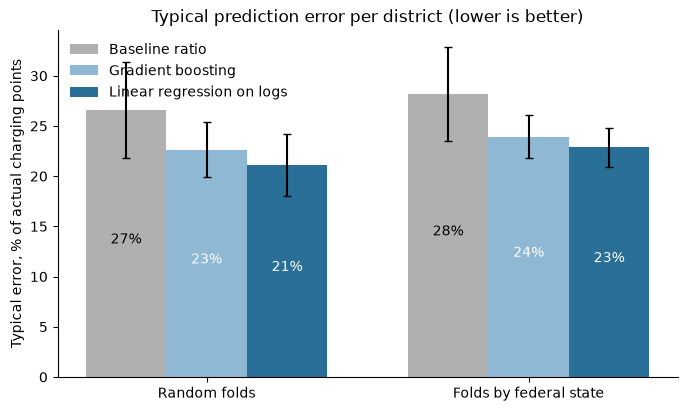

In [3]:
order = [BASELINE, BOOSTING, LINEAR]
colors = {BASELINE: "#b0b0b0", BOOSTING: "#8fb8d4", LINEAR: "#2a6f97"}
fig, ax = plt.subplots()
width = 0.25
for i, name in enumerate(order):
    values, errors = [], []
    for scores in (per_fold, per_fold_state):
        part = scores[scores["model"] == name]["median_error_pct"]
        values.append(part.mean())
        errors.append(part.std())
    positions = np.arange(2) + (i - 1) * width
    ax.bar(positions, values, width, yerr=errors, capsize=3, color=colors[name], label=name)
    for x, v in zip(positions, values):
        ax.text(x, v / 2, f"{v:.0f}%", ha="center", color="white" if name != BASELINE else "black")
ax.set_xticks(range(2), ["Random folds", "Folds by federal state"])
ax.set_ylabel("Typical error, % of actual charging points")
ax.set_title("Typical prediction error per district (lower is better)")
ax.legend(frameon=False)
plt.show()

In [4]:
# Is the difference stable, or does it depend on the random split? Repeat with 10 different splits.
rows = []
for seed in range(10):
    _, repeat = cross_validate(districts, models, random_folds(seed=seed))
    by_model = repeat.groupby("model")["median_error_pct"].mean()
    rows.append({"seed": seed, "baseline minus linear": by_model[BASELINE] - by_model[LINEAR],
                 "boosting minus linear": by_model[BOOSTING] - by_model[LINEAR]})
repeats = pd.DataFrame(rows).set_index("seed")
print("Difference in typical error, in percentage points (positive: the linear model is better)")
print(repeats.round(1).T.to_string())
print()
wins = per_fold.pivot(index="fold", columns="model", values="median_error_pct")
print("Folds (of 5) where linear beats the baseline:", int((wins[LINEAR] < wins[BASELINE]).sum()),
      "| beats gradient boosting:", int((wins[LINEAR] < wins[BOOSTING]).sum()))

Difference in typical error, in percentage points (positive: the linear model is better)
seed                     0    1    2    3    4    5    6    7    8    9
baseline minus linear  5.9  6.3  5.9  6.0  5.6  6.9  5.0  5.9  6.6  6.1
boosting minus linear  2.2  2.6  3.2  2.1  1.8  2.6  2.0  2.4  1.9  1.7

Folds (of 5) where linear beats the baseline: 5 | beats gradient boosting: 4


**What the comparison shows**

- The linear model on logs has the lowest error in both cross validation schemes. The typical error is about 21% with random folds and about 23% with folds by state.
- It beats the baseline ratio in all 5 folds and in all 10 repeated splits (by 5 to 7 percentage points). The baseline is about 27% off.
- Gradient boosting is between the two. It does not find structure that the linear model misses, and it is worse when whole states are held out. With 399 districts and 3 inputs this is plausible.
- The standard deviation over the folds is 2 to 5 percentage points, so the gap between linear and boosting (about 2 points) is small compared with the noise. Read it as "no clear gain from the flexible model", not as proof that linear is better.
- The simple model generalises about as well to unseen states (23%) as to unseen districts (21%).

**What it does not show.** A typical error of 21% is large. A district that is 20% below its expected value is within normal noise. Only large gaps are worth attention.

## 2. Does the model fit the districts?

Residual analysis for the linear model, using the out-of-fold expected values. The residual is the log of actual divided by expected points. Negative means fewer points than expected.

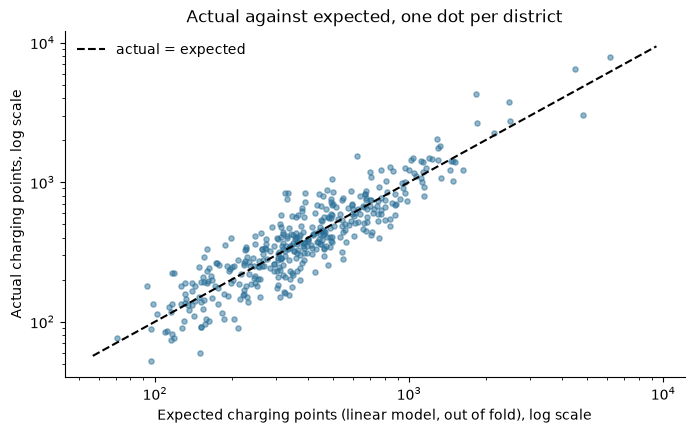

residual standard deviation (log): 0.33 | middle 80% of districts are between -34% and +50% of expected


In [5]:
gaps = build_gap_table(districts, out_of_fold)
gaps["state"] = state_of(districts)
gaps["residual"] = np.log(gaps["charging_points"] / gaps["expected_linear"])

fig, ax = plt.subplots()
ax.scatter(gaps["expected_linear"], gaps["charging_points"], s=14, alpha=0.5, color="#2a6f97")
limits = [gaps["expected_linear"].min() * 0.8, gaps["charging_points"].max() * 1.2]
ax.plot(limits, limits, color="black", linestyle="--", label="actual = expected")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Expected charging points (linear model, out of fold), log scale")
ax.set_ylabel("Actual charging points, log scale")
ax.set_title("Actual against expected, one dot per district")
ax.legend(frameon=False)
plt.show()
print("residual standard deviation (log):", round(gaps["residual"].std(), 2),
      "| middle 80% of districts are between", f"{np.exp(gaps['residual'].quantile(.1)) - 1:+.0%}", "and", f"{np.exp(gaps['residual'].quantile(.9)) - 1:+.0%}", "of expected")

In [6]:
fifths = pd.qcut(gaps["expected_linear"], 5)
check = gaps.groupby(fifths, observed=True).agg(districts=("key", "size"), mean_residual=("residual", "mean"),
                                                 median_gap_pct=("gap_pct_linear", "median"))
check.index = [f"{int(i.left)} to {int(i.right)}" for i in check.index]
check.index.name = "expected points"
print("Is the model off in one part of the range? Districts in 5 equal groups by expected points")
print(check.round(2).to_string())

Is the model off in one part of the range? Districts in 5 equal groups by expected points
                 districts  mean_residual  median_gap_pct
expected points                                          
71 to 219               80           0.02            3.49
219 to 323              80          -0.02           -0.75
323 to 444              79           0.01           -0.70
444 to 676              80           0.01           -1.58
676 to 6159             80          -0.02           -3.43


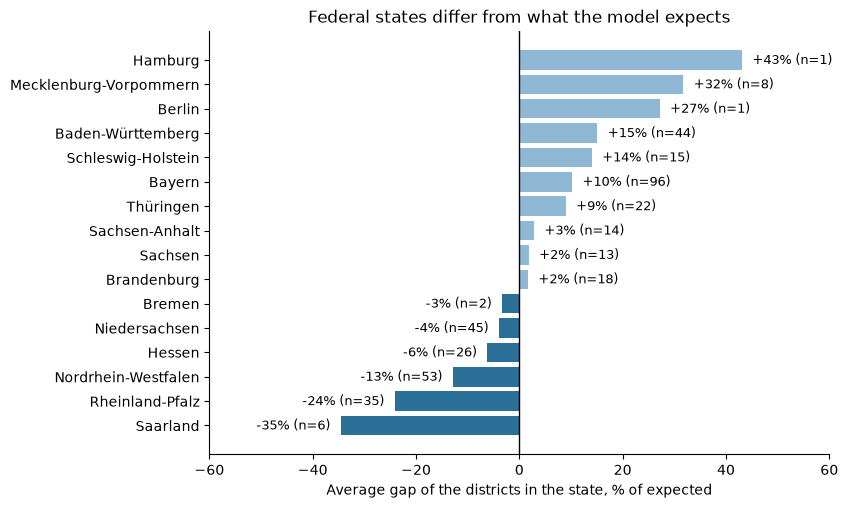

In [7]:
STATES = {"01": "Schleswig-Holstein", "02": "Hamburg", "03": "Niedersachsen", "04": "Bremen", "05": "Nordrhein-Westfalen",
          "06": "Hessen", "07": "Rheinland-Pfalz", "08": "Baden-Württemberg", "09": "Bayern", "10": "Saarland",
          "11": "Berlin", "12": "Brandenburg", "13": "Mecklenburg-Vorpommern", "14": "Sachsen",
          "15": "Sachsen-Anhalt", "16": "Thüringen"}
gaps["state_name"] = gaps["state"].map(STATES)
by_state = gaps.groupby("state_name").agg(districts=("key", "size"), mean_residual=("residual", "mean"))
by_state["vs expected"] = np.exp(by_state["mean_residual"]) - 1
by_state = by_state.sort_values("mean_residual")

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#2a6f97" if v < 0 else "#8fb8d4" for v in by_state["vs expected"]]
ax.barh(by_state.index, by_state["vs expected"] * 100, color=colors)
for y, (value, n) in enumerate(zip(by_state["vs expected"], by_state["districts"])):
    ax.text(value * 100 + (2 if value >= 0 else -2), y, f"{value:+.0%} (n={n})", va="center", ha="left" if value >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlim(-60, 60)
ax.set_xlabel("Average gap of the districts in the state, % of expected")
ax.set_title("Federal states differ from what the model expects")
plt.show()

**What the residuals show**

- The model is not systematically off in one part of the range. In each of the 5 groups of districts, by expected number of points, the average log residual is between -0.02 and +0.02. The plot looks as if the smallest districts lie more often above the line. The table shows that this is scatter, not a bias. The scatter is wide: the middle 80% of districts lie between 34% below and 50% above their expected value.
- Some federal states differ systematically. The districts of Rheinland-Pfalz and Saarland have on average clearly fewer charging points than expected, Hamburg, Berlin and Mecklenburg-Vorpommern clearly more. States with only 1 to 6 districts (Hamburg, Bremen, Berlin, Saarland) are based on very few districts, so read them with care.
- This matters for the ranking: districts of the same state are not independent. A state-wide pattern can come from state funding programmes, grid operators or other reasons. The data does not show which.
- The model does not know the state. Adding it would remove the state-wide pattern and rank districts within their state. Whether that is wanted depends on the question. Here the state pattern is kept in the gap, because a state that lags behind is also a finding.

## 3. The gap per district

Gap in percent = (actual minus expected) / expected. A gap of -50% means the district has half of the charging points that the model expects. The expected value is out of fold. In the tables, "missing points" is expected minus actual, so it is negative for districts above their expected value.

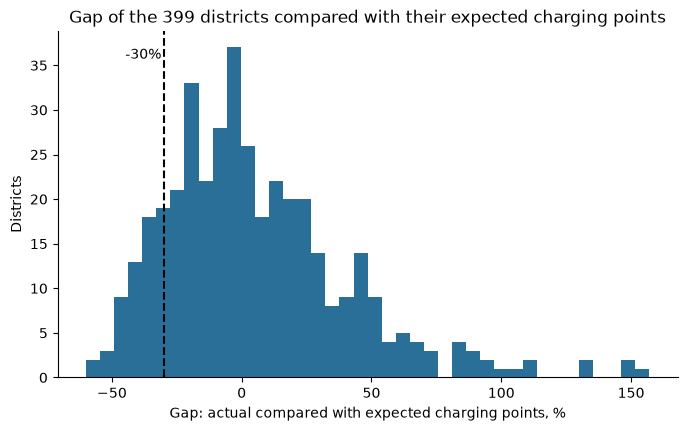

districts more than 30% below expected: 55 | more than 40% below: 24 | more than 30% above: 78


In [8]:
column = "gap_pct_linear"
fig, ax = plt.subplots()
ax.hist(gaps[column], bins=40, color="#2a6f97")
ax.axvline(-30, color="black", linestyle="--")
ax.text(-31, ax.get_ylim()[1] * 0.92, "-30%", ha="right")
ax.set_xlabel("Gap: actual compared with expected charging points, %")
ax.set_ylabel("Districts")
ax.set_title("Gap of the 399 districts compared with their expected charging points")
plt.show()
print("districts more than 30% below expected:", int((gaps[column] < -30).sum()),
      "| more than 40% below:", int((gaps[column] < -40).sum()),
      "| more than 30% above:", int((gaps[column] > 30).sum()))

In [9]:
show = ["name", "state_name", "bev", "population", "charging_points", "expected_linear", "gap_pct_linear", "missing_points_linear"]
names = {"state_name": "state", "charging_points": "actual", "expected_linear": "expected",
         "gap_pct_linear": "gap %", "missing_points_linear": "missing points"}
print("The 15 districts furthest below their expected number of charging points")
print(gaps.nsmallest(15, column)[show].rename(columns=names).round(0).to_string(index=False))
print()
print("The 5 districts furthest above")
print(gaps.nlargest(5, column)[show].rename(columns=names).round(0).to_string(index=False))

The 15 districts furthest below their expected number of charging points
                       name               state   bev  population  actual  expected  gap %  missing points
                      Kusel     Rheinland-Pfalz  1262     69334.0      60     150.0  -60.0            90.0
               Südwestpfalz     Rheinland-Pfalz  2089     89974.0      90     212.0  -58.0           122.0
                Germersheim     Rheinland-Pfalz  3364    131383.0     155     336.0  -54.0           181.0
               Wolfenbüttel       Niedersachsen  3399    118290.0     150     310.0  -52.0           160.0
  Altenkirchen (Westerwald)     Rheinland-Pfalz  3207    132125.0     161     323.0  -50.0           162.0
   Offenbach am Main, Stadt              Hessen  2497    132746.0     176     345.0  -49.0           169.0
             Krefeld, Stadt Nordrhein-Westfalen  4323    231406.0     280     548.0  -49.0           268.0
                Neunkirchen            Saarland  2645    133179.0     1

## 4. Do the models agree on the ranking?

The rank correlation says how similar two rankings are (1 is identical). The overlap counts how many of the 20 most underserved districts two models share.

Rank correlation of the gaps


                   Baseline  Linear on logs  Gradient boosting
Baseline               1.00            0.82               0.73
Linear on logs         0.82            1.00               0.92
Gradient boosting      0.73            0.92               1.00

Overlap of the 20 most underserved districts:
linear and boosting: 14 of 20
linear and baseline: 11 of 20


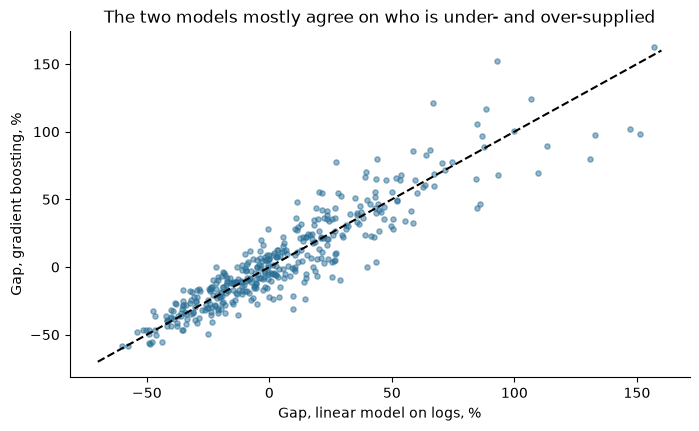

In [10]:
columns = {"Baseline": "gap_pct_baseline", "Linear on logs": "gap_pct_linear", "Gradient boosting": "gap_pct_boosting"}
rank_corr = pd.DataFrame({a: {b: gaps[ca].rank().corr(gaps[cb].rank()) for b, cb in columns.items()} for a, ca in columns.items()})
print("Rank correlation of the gaps")
print(rank_corr.round(2).to_string())

top = {name: set(gaps.nsmallest(20, col)["key"]) for name, col in columns.items()}
print()
print("Overlap of the 20 most underserved districts:")
print("linear and boosting:", len(top["Linear on logs"] & top["Gradient boosting"]), "of 20")
print("linear and baseline:", len(top["Linear on logs"] & top["Baseline"]), "of 20")

fig, ax = plt.subplots()
ax.scatter(gaps["gap_pct_linear"], gaps["gap_pct_boosting"], s=14, alpha=0.5, color="#2a6f97")
ax.plot([-70, 160], [-70, 160], color="black", linestyle="--")
ax.set_xlabel("Gap, linear model on logs, %")
ax.set_ylabel("Gap, gradient boosting, %")
ax.set_title("The two models mostly agree on who is under- and over-supplied")
plt.show()

## 5. Summary

- The linear regression on logs predicts the expected number of charging points better than the baseline ratio (typical error about 21% against about 27%). Gradient boosting does not improve on it.
- The model describes the current relationship between cars, residents and charging points. It does not show how many charging points are optimal. A district can be below its expected value and still be well supplied, or the other way round.
- Typical error is about 21%. Only large gaps are meaningful. About 55 of 399 districts are more than 30% below their expected value, and about 24 are more than 40% below.
- The list is shaped by state-wide patterns (many districts of Rheinland-Pfalz and Saarland at the top).
- Cars are counted by place of registration and charging points are the public points of the register. Company registrations, commuters, tourism and home charging are not in the data.
- The reference dates differ: cars 01.01.2026, charging points 12.11.2026, population 31.12.2024.

**Next:** sensitivity check with plug-in hybrids, then the ranked list with the value estimate (assumptions marked).

### Appendix: coefficients of the linear model

Fitted on all 399 districts, for reading only. The evaluation above does not use this fit. The coefficients are elasticities: if the input is 10% higher, the expected charging points are about (coefficient x 10)% higher.

In [11]:
final = make_models()[LINEAR].fit(districts[config.FEATURE_COLUMNS], districts[config.TARGET])
linear_step = final.regressor_.steps[-1][1]
print(pd.Series(linear_step.coef_, index=config.FEATURE_COLUMNS, name="elasticity").round(3).to_string())
print("intercept (log):", round(linear_step.intercept_, 2))
print("BEV and population correlate at", round(np.log(districts["bev"]).corr(np.log(districts["population"])), 2), "(log values), so the individual coefficients are not stable.")

bev           0.480
population    0.446
density       0.071
intercept (log): -3.73
BEV and population correlate at 0.89 (log values), so the individual coefficients are not stable.
